# 09 · State asking prices after accounting for vehicle mix

## Research question 4
How do asking prices vary by state, and how do state comparisons change when we benchmark each listing against comparable vehicle attributes? See the [proposal](../docs/proposal.md) and [data source](../DATA.md). A state is the listing's recorded state. The data cover roughly one month of Craigslist activity.

## Two quantities with different meanings

- **Raw median:** the median among all positive listings in a state from the pinned snapshot.
- **Adjusted gap:** 100 × (exp(median(log observed price − log predicted price)) − 1) among supported April validation listings in that state. A positive gap means the observed asking price tends to be above the benchmark for its recorded attributes. The benchmark omits state and other geography fields. It uses age, mileage, manufacturer, condition, fuel, vehicle type, title status, transmission, and drivetrain.

The adjusted gap depends on observed vehicle attributes, sample coverage and the model. Use the same supported sample for any change in state rank.

In [1]:
from pathlib import Path
import json
import sys

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "research_data.py").is_file()), None)
if root is None:
    raise RuntimeError("Start Jupyter from the repository or notebooks directory.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from src.research_data import load_research_data
from src.research_models import model_cohort, run_experiment
from src.research_figures import (
    figure_style, save_figure, state_intervals, state_maps,
    state_model_sensitivity, state_rank_shifts,
)
from src.state_prices import load_state_paths, summarize_states, MIN_STATE_N

figure_style()
directory = root / "outputs" / "q4"
directory.mkdir(parents=True, exist_ok=True)
raw = load_research_data(root)
cohort = model_cohort(raw)
(predictions,) = run_experiment(root, cohort, "states")
print(f"All positive listings: {len(raw):,}")
print(f"April out-of-fold prices in the selected band: {len(predictions):,}")


All positive listings: 393,985
April out-of-fold prices in the selected band: 226,317


## Scope, support and uncertainty

The geography models predict three six-day April blocks from earlier listings only. Each training block excludes possible test matches by VIN or exact attribute fingerprint. Both benchmarks fit log asking price, and use the same dated $500–$150,000 target cohort.

The support screen requires at least 100 earlier records with the same known make and vehicle type. Age and mileage must fall inside that training cell's 1st–99th percentile ranges. This screens sparse or extrapolated examples on each feature and narrows the population being described. The state comparison requires at least 100 supported listings per state.

Intervals resample opaque vehicle groups within a state, with 399 draws. Adjusted intervals condition on the saved out-of-fold predictions. They capture resampling variation within this sample and do not include model refitting, rank multiplicity or platform selection.

In [2]:
summary, blocks = summarize_states(raw, predictions, draws=399)
coverage = predictions.groupby("window")["supported"].agg(april_n="size", supported_n="sum")
coverage["supported_pct"] = 100 * coverage["supported_n"] / coverage["april_n"]
display(coverage.round(1))
print(f"{summary['gap_pct'].notna().sum()} states or districts meet the adjusted sample threshold.")


51 states or districts meet the adjusted sample threshold.


,april_n,supported_n,supported_pct
window,,,
Apr 13–18,51432,32098,62.4
Apr 19–24,74265,47540,64.0
Apr 25–30,100620,68957,68.5


## 1 · Where asking prices are high

The first map uses dollars and all positive listings. The second uses a zero-centered percentage scale and supported April listings. DC is marked at its actual location with an enlarged dot. The Albers projection includes Alaska and Hawaii as insets. Boundary source: [U.S. Atlas 3.0.1](https://github.com/topojson/us-atlas), derived from U.S. Census cartographic boundaries.

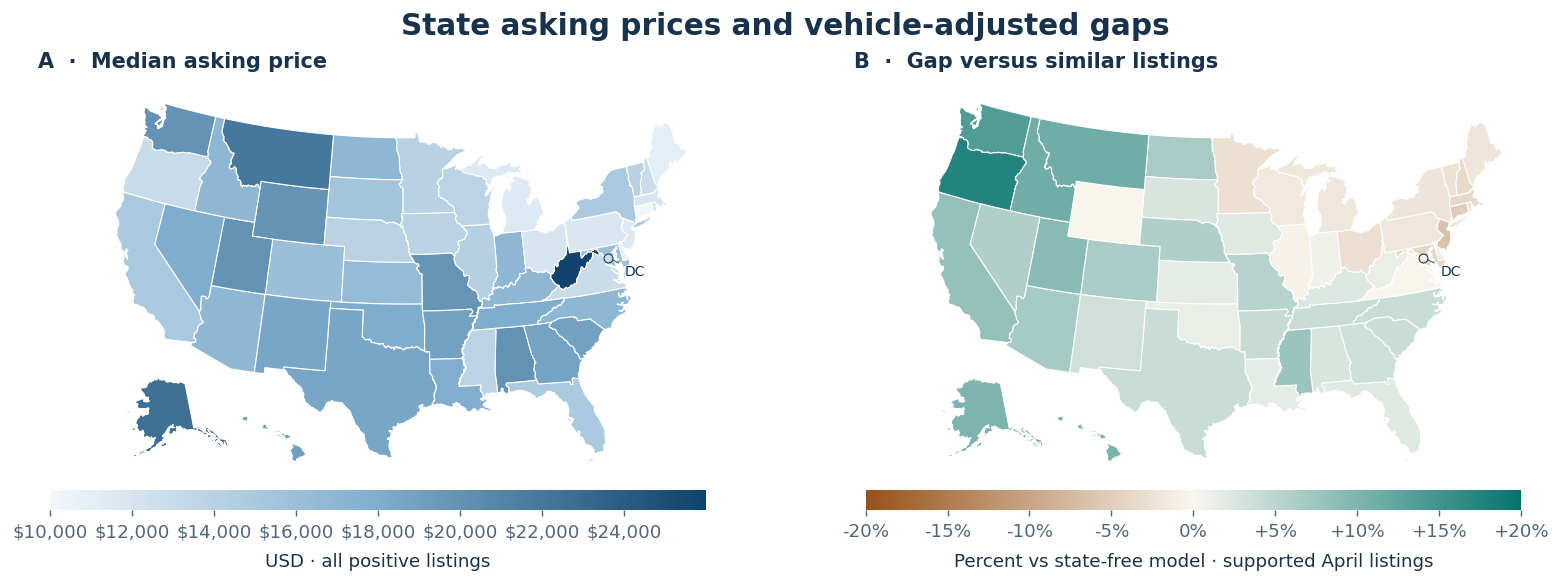

In [3]:
fig = state_maps(summary, load_state_paths(root))
save_figure(fig, directory, "state_price_maps")
plt.show()


## 2 · Check the differences with intervals and counts

Read the left and right columns on their own scales. The right-hand whiskers are conditional intervals for the adjusted gap. Use the full table export to check the estimate, interval and retained count for every state.

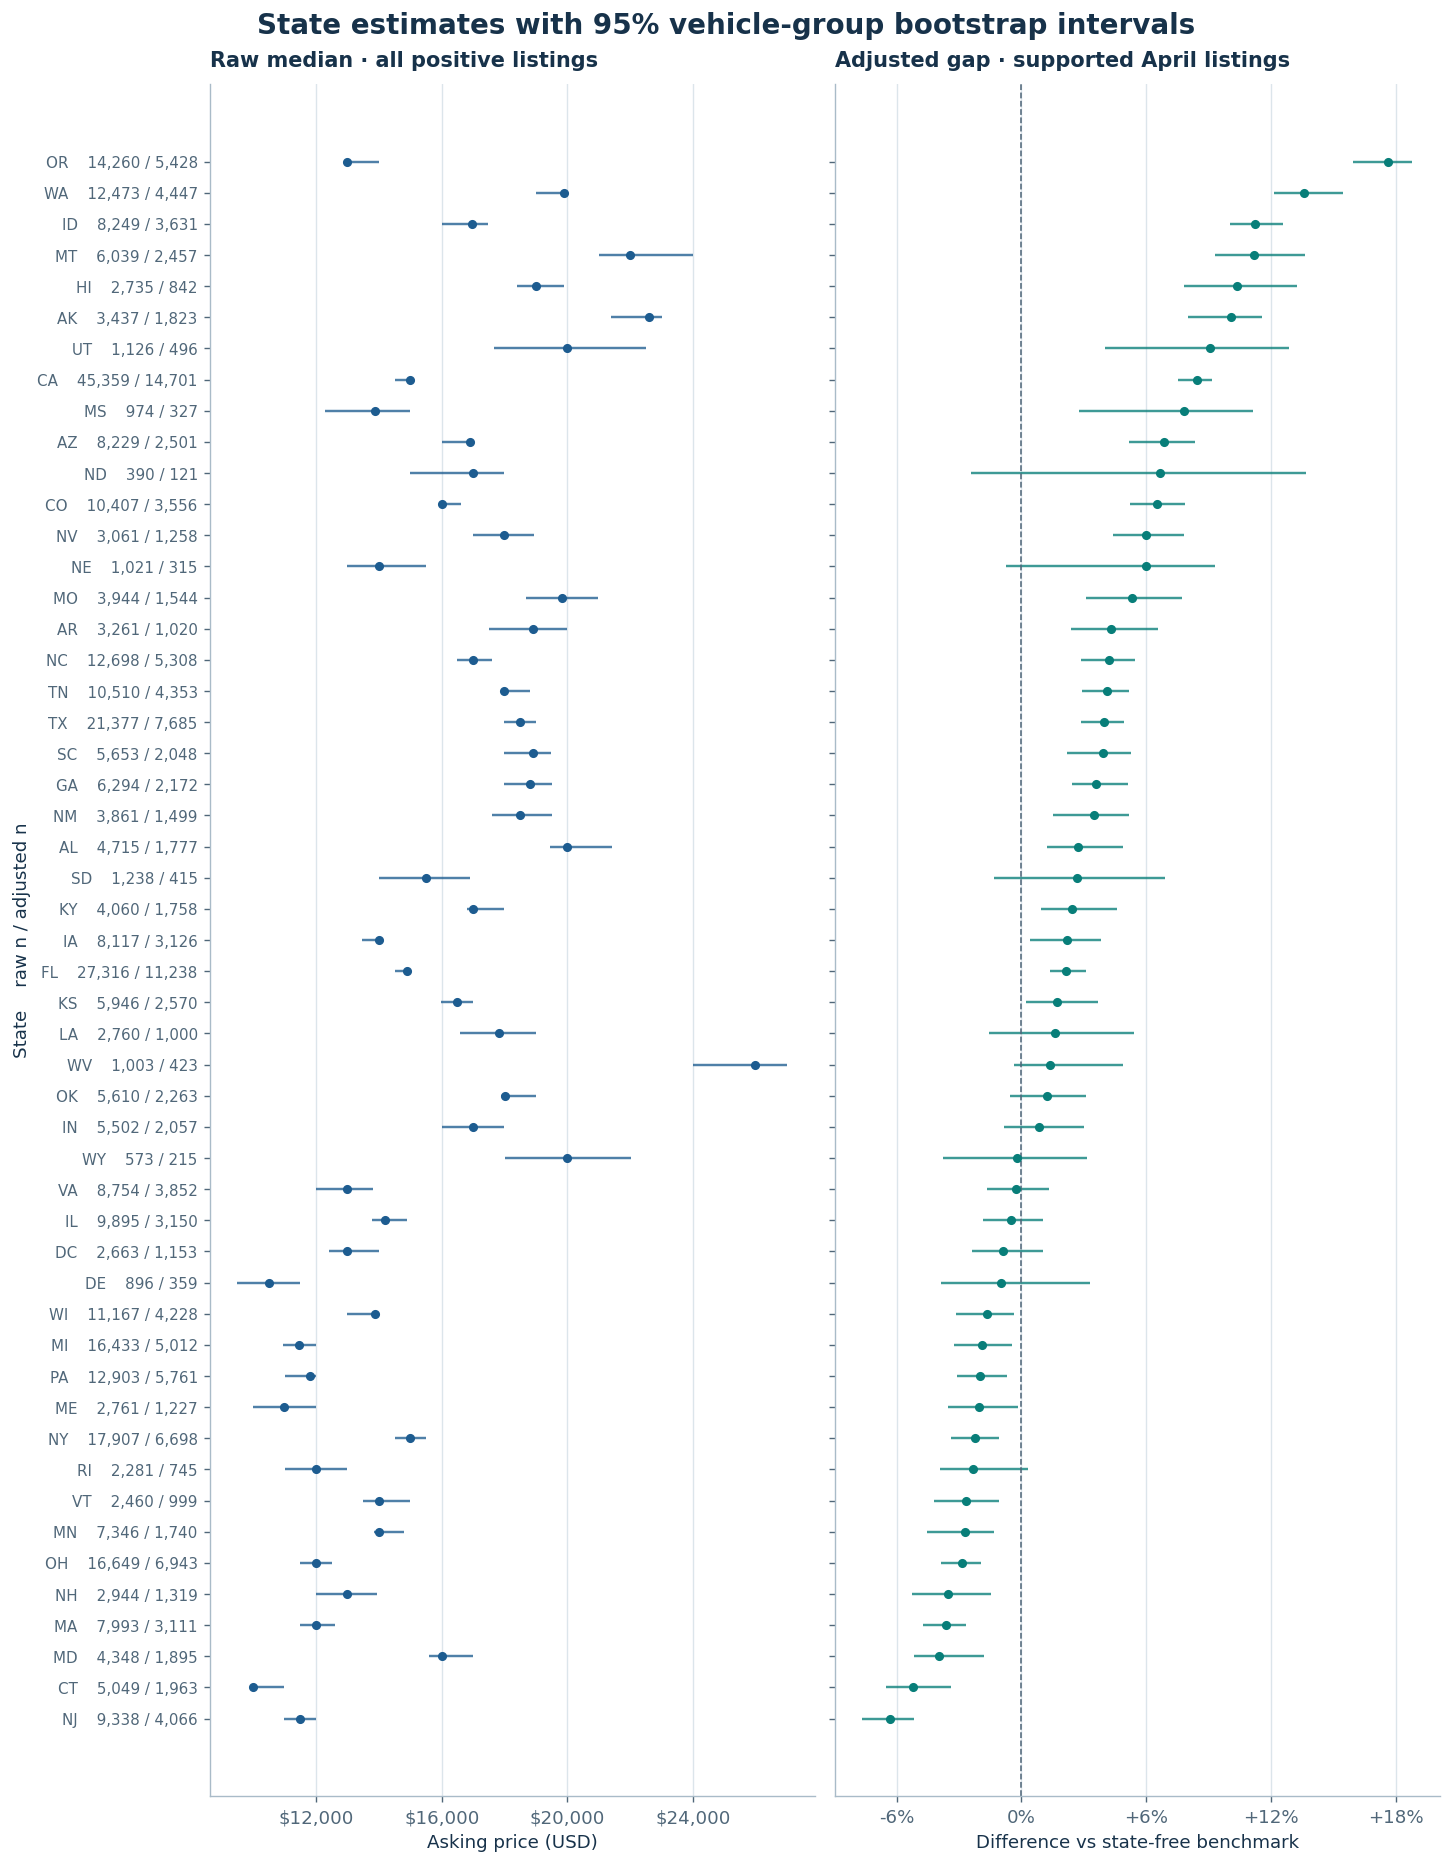

In [4]:
fig = state_intervals(summary)
save_figure(fig, directory, "state_intervals")
plt.show()


## 3 · Compare ranks on the same listings

Rank 1 means highest. Both the raw and adjusted ranks here use the same supported April listings. The chart shows the twelve largest absolute shifts. Adjacent ranks can be close in price or in percentage gap, so the interval plot and effect sizes matter more than rank alone.

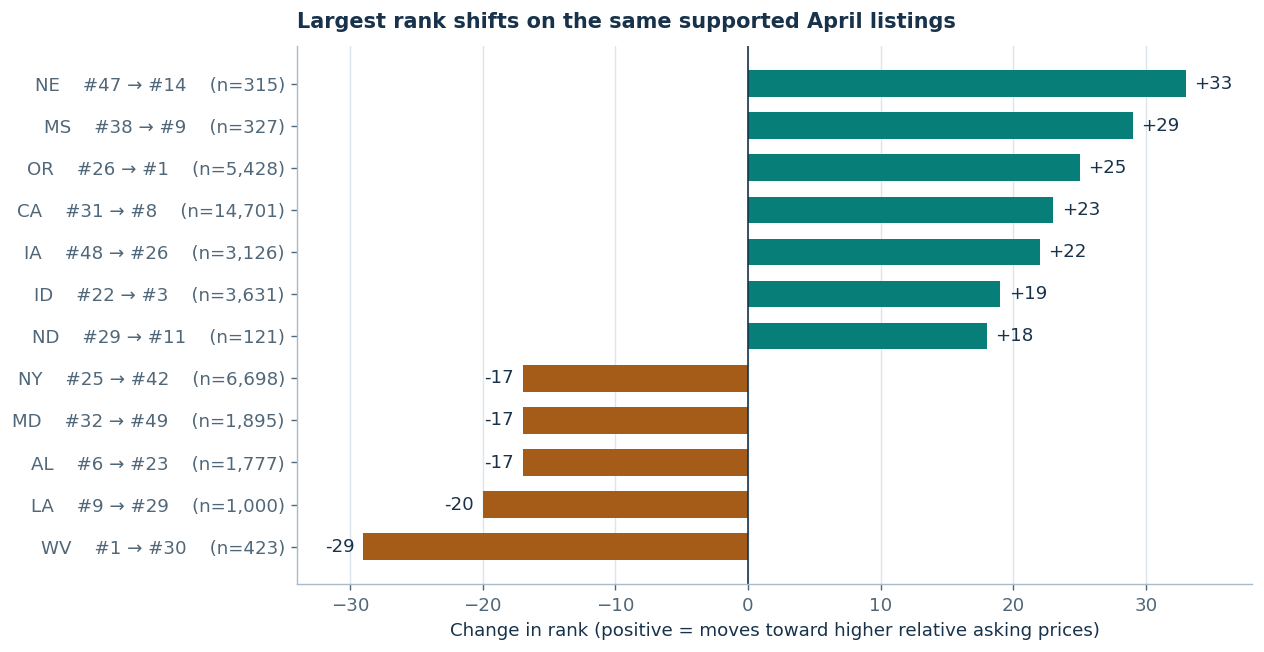

In [5]:
fig = state_rank_shifts(summary)
save_figure(fig, directory, "state_rank_changes")
plt.show()


## 4 · Test robustness to model, time window and support

Ridge and histogram gradient boosting use the same earlier rows and state-free feature list. The heatmap shows each selected state's gaps separately by validation block. Fewer than 50 supported observations leaves a block cell blank. We also compare the main supported estimates with the broader in-band April cohort.

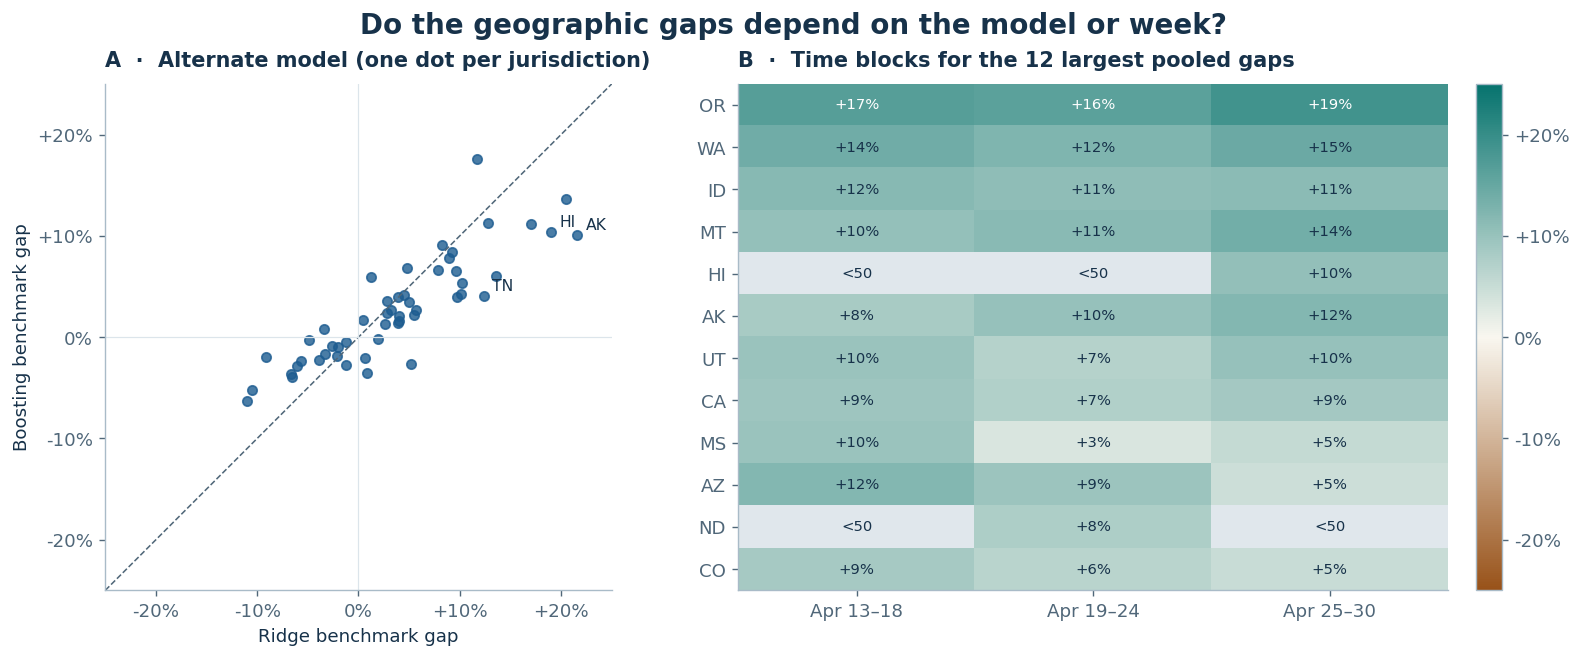

,supported_n,raw_supported,gap_pct,gap_low,gap_high,raw_rank,gap_rank,ridge_gap_pct
state,,,,,,,,
ne,315,13750.0,6.0,-0.8,9.3,47.0,14.0,1.3
ms,327,15900.0,7.8,2.8,11.1,38.0,9.0,9.0
wv,423,29590.0,1.4,-0.3,4.9,1.0,30.0,3.9
or,5428,17750.0,17.6,16.0,18.8,26.0,1.0,11.7
ca,14701,16800.0,8.4,7.5,9.2,31.0,8.0,9.2
ia,3126,12995.0,2.2,0.4,3.8,48.0,26.0,5.5


In [6]:
fig = state_model_sensitivity(summary, blocks)
save_figure(fig, directory, "state_gap_sensitivity")
plt.show()
eligible = summary.dropna(subset=["gap_pct"])
rank_corr = eligible["raw_rank"].rank().corr(eligible["gap_rank"].rank())
model_corr = eligible["gap_pct"].rank().corr(eligible["ridge_gap_pct"].rank())
broad_corr = eligible["gap_pct"].rank().corr(eligible["all_april_gap_pct"].rank())
largest = eligible.loc[eligible["rank_change"].abs().nlargest(6).index]
display(largest[["supported_n", "raw_supported", "gap_pct", "gap_low",
                 "gap_high", "raw_rank", "gap_rank", "ridge_gap_pct"]].round(1))
summary.to_csv(directory / "state_estimates.csv")
blocks.to_csv(directory / "state_block_sensitivity.csv", index=False)


## Takeaways

In [7]:
low = eligible["gap_pct"].idxmin()
high = eligible["gap_pct"].idxmax()
raw_lo = summary["median_all"].idxmin()
raw_hi = summary["median_all"].idxmax()
largest_shift = eligible["rank_change"].abs().idxmax()
a = eligible.loc[largest_shift]
display(Markdown(
    f"- Raw medians span **${summary.loc[raw_lo, 'median_all']:,.0f} ({raw_lo.upper()})** "
    f"to **${summary.loc[raw_hi, 'median_all']:,.0f} ({raw_hi.upper()})**.\n"
    f"- The benchmark gaps span **{eligible.loc[low, 'gap_pct']:+.1f}% ({low.upper()})** "
    f"to **{eligible.loc[high, 'gap_pct']:+.1f}% ({high.upper()})**. "
    f"Raw and adjusted ranks on the same listings have Spearman ρ = **{rank_corr:.2f}**. "
    f"{largest_shift.upper()} moves from #{a.raw_rank:.0f} to #{a.gap_rank:.0f}.\n"
    f"- Gap ranks correlate at **{model_corr:.2f}** across models and **{broad_corr:.2f}** "
    f"between supported and broader April samples. These comparisons describe one short listing snapshot."
))
aggregate = {
    "positive_n": len(raw), "april_oof_n": len(predictions),
    "supported_n": int(predictions["supported"].sum()), "eligible_states": len(eligible),
    "raw_low": {"state": raw_lo, "median": float(summary.loc[raw_lo, "median_all"])},
    "raw_high": {"state": raw_hi, "median": float(summary.loc[raw_hi, "median_all"])},
    "adjusted_low": {"state": low, "gap_pct": float(eligible.loc[low, "gap_pct"])},
    "adjusted_high": {"state": high, "gap_pct": float(eligible.loc[high, "gap_pct"])},
    "rank_spearman": float(rank_corr), "model_spearman": float(model_corr),
    "support_spearman": float(broad_corr), "biggest_shift": largest_shift,
    "biggest_raw_rank": int(a.raw_rank), "biggest_gap_rank": int(a.gap_rank),
}
(directory / "summary.json").write_text(json.dumps(aggregate, indent=2), encoding="utf-8")


- Raw medians span **$10,000 (CT)** to **$25,990 (WV)**.
- The benchmark gaps span **-6.3% (NJ)** to **+17.6% (OR)**. Raw and adjusted ranks on the same listings have Spearman ρ = **0.61**. NE moves from #47 to #14.
- Gap ranks correlate at **0.88** across models and **0.93** between supported and broader April samples. These comparisons describe one short listing snapshot.